The purpose of this notebook is to extract correlation values form the himalaya pipeline.
Using the Glasser ROIs

In [1]:
import os, glob
from os.path import join
import numpy as np
import pandas as pd
import seaborn as sns

from neuromaps.datasets import fetch_fslr
import numpy as np
from neuromaps.datasets import fetch_fsaverage
from surfplot import Plot
import nibabel as nib
from neuromaps.datasets import fetch_fslr
from surfplot import Plot

import matplotlib.pyplot as plt

In [3]:
# feature_vertex_count = {'scenes': ([ 7328,  8524,  3696,  5424, 10498, 10501,  6131,  3940,  8783,
#          7825,  3820,  6443,  8026,  5516,  5479,  4707,  5754,  3401,
#          4354,  3601,  4936,  7304, 12325,  5212,  4969,  5915,  8415,
#          4545,  2659,  3573,  8048,  3823,  6061,  8340,  8085,  3867,
#          6019,  6233,  8496,  8970,  4440,  9860,  6744,  3207,  6740,
#          5647,  5379,  7930,  4911,  8278,  5811,  7482,  5884,  4170,
#          7230,  3176,  9198,  3964,  4963,  4090,  5008,  9151,  4324,
#          4007,  4633,  6138,  7398,  3483,  4396,  6883, 10406,  3844]),
#  'moten': ([ 9841,  9779, 12600,  9779,  5392,  6065,  3531, 10598,  8255,
#          7245,  9950,  9783, 10006, 10111, 14126, 11876,  8971, 14633,
#         15268, 15347, 12045,  9279,  4842,  8986,  7593,  9386, 13177,
#          6727, 18463,  8300,  9136, 13259,  7634,  9909,  8199,  8938,
#         16131,  6907,  6913,  5407, 13133,  9114, 11319, 10308,  7822,
#         13964, 10448, 10830, 10279,  8274, 12272, 11033,  9930,  5729,
#         13755,  8464,  5639,  8604, 10157, 11418,  9371, 10321,  9115,
#          5338,  8521,  6247,  9128,  8472, 15306,  7228,  7082,  6849]),
#  'actions': ([ 6550, 10392,  6997, 10047,  7071,  6933, 12030,  8933, 10567,
#          8434,  7289,  6878, 12000, 10349,  8094,  9094,  8672,  7707,
#          5751, 10061,  6351,  5631,  5867,  5088,  9376,  9422,  4626,
#          7372,  6024,  8228,  8078,  3496,  7973, 10735,  6332,  8692,
#          5226, 10404,  8937,  8998,  3928,  7209,  5695,  8664,  5416,
#          5615,  8916,  7309,  9119,  8946,  8640,  6777,  4790, 14944,
#          5180,  7353,  6714, 12396,  8760,  5802,  6569,  9325,  9727,
#         18177,  8345,  9551,  7184, 10729,  4321,  6861,  8811, 12076]),
#  'objects': ([ 4723,  3468,  9035,  6809, 10354,  5234, 11938,  5903,  6133,
#          9736,  9920,  8899,  3717,  5907,  5889,  7216,  4929,  7314,
#          4262,  6711,  8162,  9310,  7034, 11470,  8620,  8699,  3855,
#         12971,  5695,  9273,  5912, 12051,  8817,  4297,  9887,  9311,
#          7359,  8263,  8628,  9782,  7886,  4696,  7163, 12608,  6869,
#          7860,  8368,  7534,  8291,  9472,  7462,  6550,  9872,  5678,
#          7870, 11020, 10630,  6082,  6975,  8018,  7474,  3655,  7509,
#          5431,  4869,  7214,  9186,  9217,  6838,  9246,  5879,  7463]),
#  'agents': ([ 9029,  5308,  5143,  5412,  4156,  8738,  3841,  8097,  3733,
#          4231,  6492,  5468,  3722,  5588,  3883,  4578,  9145,  4416,
#          7836,  1751,  5977,  5947,  7403,  6715,  6913,  4049,  7398,
#          5856,  4630,  8097,  6297,  4842,  6986,  4190,  4968,  6663,
#          2736,  5664,  4497,  4314,  8084,  6592,  6550,  2684, 10624,
#          4385,  4360,  3868,  4871,  2501,  3286,  5629,  6995,  6950,
#          3436,  7458,  5290,  6425,  6616,  8143,  9049,  5019,  6796,
#          4518, 11103,  8321,  4575,  5570,  6610,  7253,  5293,  7239])}

In [2]:
feature_vertex_count = {'scenes': ([13053, 15334,  8730,  9601, 22716, 19758, 12193,  7599, 16670,
        14781,  8125, 15209, 12846, 12065,  8799,  9799, 12550,  7726,
         8930,  7037, 11124, 12711, 22898, 10407, 10489, 10417, 16984,
         8414,  5450,  8745, 15808,  7958, 11834, 14536, 16419,  8400,
        15215, 10888, 14952, 22370,  8574, 20522, 13493,  6225, 13887,
        11168, 10512, 16681, 11459, 13111, 10665, 16572, 11824,  9167,
        14224,  6554, 16381,  9449,  9249,  8337, 10371, 16537,  8337,
         7335,  8729, 11693, 16290,  6365,  9575, 10954, 21615,  7751]),
 'moten': ([20979, 19397, 23776, 22339, 11131, 13356, 13141, 23308, 16520,
        16168, 20593, 18064, 19587, 19327, 30709, 23319, 18094, 28215,
        31337, 29335, 21788, 20127, 10135, 19444, 14435, 17674, 23860,
        15813, 35086, 17275, 17997, 24761, 16219, 24579, 16412, 14948,
        31899, 16061, 16529,  9950, 26022, 15648, 22464, 21218, 14439,
        26941, 23212, 21688, 20889, 18365, 24759, 19595, 21573, 12404,
        25171, 18167, 13541, 18633, 22918, 24234, 20508, 21753, 18829,
        12734, 16904, 13255, 19566, 19959, 26975, 16637, 13333, 16518]),
 'actions': ([12498, 20678, 13563, 16617, 14147, 14335, 21635, 18236, 20601,
        16169, 12653, 13803, 28244, 19868, 16394, 20080, 19004, 16872,
        11983, 18831, 14522, 15059, 10267, 11388, 16252, 20653, 12253,
        16075, 14652, 19992, 17161,  6448, 14658, 21140, 14871, 19741,
         9756, 16922, 16985, 17234, 10099, 16178, 12881, 16296, 11507,
        11629, 14758, 14720, 16138, 22482, 19350, 13912, 10862, 28984,
         9934, 16393, 12781, 23301, 17478, 10699, 11473, 17364, 22177,
        33728, 18890, 21023, 13006, 17892, 11229, 13311, 17687, 23156]),
 'objects': ([ 8722,  8320, 17744, 15237, 19538, 10162, 19857, 10382, 12667,
        16459, 18924, 18882,  6909, 11790, 11526, 13017, 10377, 15978,
         9568, 13900, 15204, 16373, 17438, 22260, 19314, 18204,  7798,
        24267, 11246, 15729, 12208, 24971, 19782,  7549, 17217, 19072,
        12812, 16683, 17836, 17882, 15336, 10126, 14056, 23119, 15135,
        15117, 17802, 13635, 16424, 16267, 15137, 12370, 17996, 11601,
        18953, 20704, 19728, 12475, 13217, 17381, 15830, 10296, 13981,
        13401,  9599, 13949, 14364, 19896, 13991, 19467, 10640, 13642]),
 'agents': ([19695, 11218, 11134, 11153,  7415, 17336,  8121, 15422,  8489,
        11370, 14652,  8989,  7361, 11897,  7519,  8732, 14922,  6156,
        13129,  5844, 12309, 10677, 14209, 11448, 14457,  7999, 14052,
        10378,  8513, 13206, 11773, 10809, 12454,  7143, 10028, 12786,
         5265, 14393,  8645,  7511, 14916, 12473, 12053,  8089, 19979,
        10092,  8663,  8223, 10037,  4722,  5036, 12498, 12692, 12791,
         6665, 13129, 12516, 11089, 12085, 14296, 16765,  8997, 11623,
         7749, 20825, 15027, 11721, 10835, 13177, 14578, 11672, 13880])}

In [3]:
df = pd.DataFrame(feature_vertex_count)
df_long = df.melt(var_name='feature', value_name='count')
df_long
df

,scenes,moten,actions,objects,agents
0,13053,20979,12498,8722,19695
1,15334,19397,20678,8320,11218
2,8730,23776,13563,17744,11134
3,9601,22339,16617,15237,11153
4,22716,11131,14147,19538,7415
...,...,...,...,...,...
67,6365,19959,17892,19896,10835
68,9575,26975,11229,13991,13177
69,10954,16637,13311,19467,14578
70,21615,13333,17687,10640,11672


In [4]:
df.mean()

scenes     12127.027778
moten      19896.375000
actions    16438.305556
objects    15131.097222
agents     11354.194444
dtype: float64

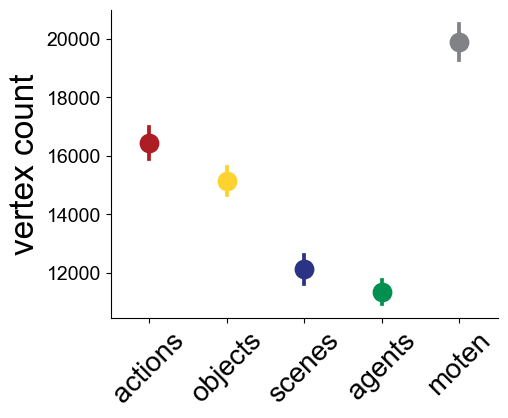

In [6]:
fig, ax = plt.subplots(figsize=(5,4))
import matplotlib
matplotlib.rcParams['font.family'] = 'Arial'
matplotlib.rcParams['font.size'] = 24
matplotlib.rcParams['ytick.labelsize'] = 14
matplotlib.rcParams['xtick.labelsize'] = 14
color_dict = {
    'actions': '#ac1e23',
    'scenes': '#2a3384',
    'agents':'#029051',
    'objects': '#fed32f',
    'moten': '#808285'

    }

feature_order = ['actions', 'objects','scenes', 'agents', 'moten']
sns.pointplot(x="feature", 
              y="count", 
              data=df_long,
              errorbar = 'se',
              order=feature_order, 
              hue='feature',
              palette=color_dict,
              ax=ax,

            )
ax.get_legend().remove()
ax.tick_params(axis='x', rotation=45, labelsize=20)
ax.set_ylabel('vertex count')
ax.set_xlabel('')
plt.setp(ax.collections, sizes=[150])
sns.despine(ax=ax)
fig.savefig('/Users/h/Documents/projects_local/life-encoding/figure/revision/count/countvertex.svg', format='svg', bbox_inches='tight')